In [2]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal, List, Sequence, Annotated

creat the state

In [3]:
class EmployeeState(TypedDict):
    name: str
    salary: float
    age:int
    decision:Literal["std_hr", "forced_hr"]
    result:str

In [4]:
def analyze_employee(state:EmployeeState)->EmployeeState:
    age=state['age']
    salary=state['salary']
    if age<=30 and salary<=40000:
        state['decision']="std_hr"
    else:
        state['decision']="forced_hr"
    print(f"le dossier de {state['name']} a ete analyse")    
    return state        

In [5]:
def standard_hr_process(state:EmployeeState):
    state['result']=f"le dossier de {state['name']} a ete traite de maniere standard"
    print("*"*80)
    print(f"le dossier de {state['name']} a ete traite de maniere standard")
    print("*"*80)
    return state


In [6]:
def forced_hr_process(state:EmployeeState):
    state['result']=f"le dossier de {state['name']} a ete traite de maniere urgente"
    print("="*80)
    print(f"le dossier de {state['name']} a ete traite de maniere urgente")
    print("="*80)
    return state

In [7]:
def router(state:EmployeeState):
    return state['decision']

In [8]:
workflow=StateGraph(EmployeeState)
workflow.add_node("analyze_node", analyze_employee)
workflow.add_node("standard_hr_node",standard_hr_process)
workflow.add_node("forced_hr_node",forced_hr_process)
workflow.add_edge(START,"analyze_node")
workflow.add_conditional_edges(
    "analyze_node",
    router,
    {
        "std_hr":"standard_hr_node",
        "forced_hr":"forced_hr_node"
    }
)
workflow.add_edge("standard_hr_node",END)
workflow.add_edge("forced_hr_node",END)

graph=workflow.compile()

In [9]:
from IPython.display import Image

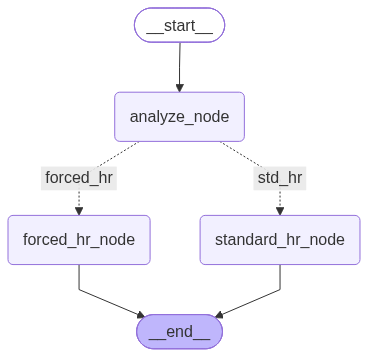

In [10]:
display(Image(graph.get_graph().draw_mermaid_png()))

le test:

In [12]:
result=graph.invoke({
    "name":"meryem", "age":25, "salary":40000
})

le dossier de meryem a ete analyse
********************************************************************************
le dossier de meryem a ete traite de maniere standard
********************************************************************************


Create agent

agent_tool

In [23]:
from langchain.tools import tool
from langchain.messages import SystemMessage, AIMessage, ToolMessage
from langchain_core.messages import BaseMessage, AnyMessage
from langgraph.graph import add_messages
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.prebuilt import ToolNode
from dotenv import load_dotenv
load_dotenv(override=True)

True

In [24]:
@tool
def somme(a:int, b:int):
    """Add two integers a and b 
    """
    print(f"Adding {a} to {b}")
    return a+b

@tool
def produit(a:int, b:int):
    """Multiply two integers a and b 
    """
    print(f"Multiplying {a} by {b}")
    return a*b

@tool
def qotient(a:int, b:int):
    """Dividing two integers a and b 
    """
    print(f"Dividing {a} by {b}")
    return a/b

tools=[somme, produit, qotient]

In [25]:
class AgentState(TypedDict):
    messages:Annotated[Sequence[BaseMessage], add_messages]

In [35]:
llm = ChatGoogleGenerativeAI(model="gemini-3.8-flash", temperature=0)
llm_with_tools = llm.bind_tools(tools=tools)

In [36]:
def assistant(state: AgentState) -> AgentState:
    response = llm_with_tools.invoke(state['messages'])
    print("#"*40)
    print("LLM invoked")
    return {"messages": [response]}

In [37]:
def should_continue(state:AgentState):
    last_message=state['messages'][-1]
    if not last_message.tool_calls:
        return "end"
    else:
        return "continue"

In [38]:
workflow = StateGraph(AgentState)
workflow.add_node("assistant", assistant)
workflow.add_node("tools", ToolNode(tools=tools))
workflow.add_edge(START, "assistant")
workflow.add_conditional_edges(
    "assistant",
    should_continue,
    {
        "end": END,
        "continue": "tools"
    }
)
workflow.add_edge("tools", "assistant")
graph = workflow.compile()

In [40]:
from langchain_core.messages import HumanMessage
res = graph.invoke({"messages": [HumanMessage(content="Combien font 24 moins 5, fois 8 ?")]})
print(res["messages"][-1].content)

GoogleAPIError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}